In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import json


# Configuring display settings
plt.rcParams['figure.figsize'] = (12, 9)
sns.set()
sns.set_context('talk')
np.set_printoptions(threshold=20, precision=2, suppress=True)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)
pd.set_option('display.float_format', '{:.2f}'.format)
warnings.filterwarnings("ignore", category=FutureWarning)


In [10]:
# Import config variable
with open("../../config.json") as f:
    cfg = json.load(f)
    
target = cfg["rc"]        
file_name = cfg["rc_file_name"]   
random_state = cfg["split"]["random_state"]  
# Load the dataset
data = pd.read_csv(f"../../data/{file_name}.csv")

In [11]:
from sklearn.model_selection import train_test_split
import numpy as np

X = data.drop(columns=[target])
y = data[target]

# Tirage de 4 seeds aléatoires différentes
master_rng = np.random.default_rng(seed=99)
seeds = master_rng.choice(10000, size=4, replace=False).tolist()
print("Seeds sélectionnées :", seeds)

# Split fixe utilisé par la grille de recherche ci-dessous
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

Seeds sélectionnées : [5650, 7575, 5059, 9578]
Training set size: 265 samples
Test set size: 67 samples


Fitting 5 folds for each of 1296 candidates, totalling 6480 fits
Meilleurs paramètres: {'colsample_bytree': 0.6, 'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 800, 'reg_alpha': 1.0, 'reg_lambda': 2.0, 'subsample': 0.7}
Meilleur R² (CV): 0.8271071798445802

MAE (test): 1.731194497293501
RMSE (test): 2.415383472853116
R² (test): 0.9167985116400068
R² (train): 0.9415481183645198


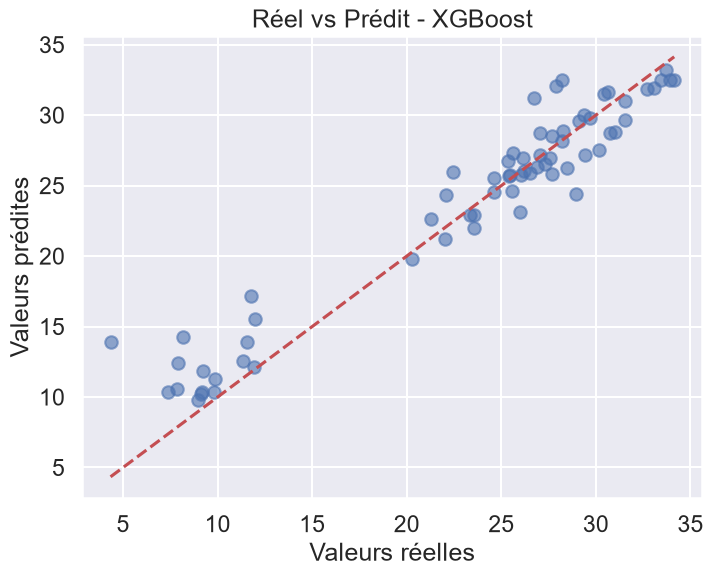

In [12]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

param_grid = {
    'n_estimators': [800, 1000, 1500],
    'learning_rate': [0.005, 0.01],
    'max_depth': [2, 3, 4],
    'min_child_weight': [5, 7, 10],
    'colsample_bytree': [0.5, 0.6],
    'subsample': [0.6, 0.7],
    'reg_alpha': [1.0, 2.0, 3.0], 
    'reg_lambda': [2.0, 3.0],
}


grid_search = GridSearchCV(
    XGBRegressor(),
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Meilleurs paramètres:", grid_search.best_params_)
print("Meilleur R² (CV):", grid_search.best_score_)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

print("\nMAE (test):", mean_absolute_error(y_test, y_pred_best))
print("RMSE (test):", np.sqrt(mean_squared_error(y_test, y_pred_best)))
print("R² (test):", r2_score(y_test, y_pred_best))
print("R² (train):", r2_score(y_train, best_model.predict(X_train)))

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Réel vs Prédit - XGBoost')
plt.show()


In [13]:
import joblib

joblib.dump(best_model, 'saved_models/xgboost_rc.pkl')

['saved_models/xgboost_rc.pkl']

In [14]:
from lightgbm import LGBMRegressor

best_model_lgb = LGBMRegressor(
    n_estimators=1500,
    learning_rate=0.01,
    max_depth=3,
    num_leaves=15,  # LightGBM n'a pas max_depth "direct", c'est via num_leaves
    min_child_samples=5,
    subsample=0.7,
    colsample_bytree=0.6,
    reg_alpha=1.0,
    reg_lambda=2.0,
    random_state=42
)

best_model_lgb.fit(X_train, y_train)
y_pred_lgb = best_model_lgb.predict(X_test)

print("R² test:", r2_score(y_test, y_pred_lgb))
print("R² train:", r2_score(y_train, best_model_lgb.predict(X_train)))

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000070 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 197
[LightGBM] [Info] Number of data points in the train set: 265, number of used features: 17
[LightGBM] [Info] Start training from score 23.017774
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best ga

In [15]:
import joblib

joblib.dump(best_model, 'saved_models/lightgbm_rc.pkl')

['saved_models/lightgbm_rc.pkl']

In [ ]:
import joblib
import os
from sklearn.model_selection import train_test_split, GridSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

os.makedirs('saved_models', exist_ok=True)

param_grid = {
    'n_estimators': [800, 1000, 1500],
    'learning_rate': [0.005, 0.01],
    'max_depth': [2, 3, 4],
    'min_child_weight': [5, 7, 10],
    'colsample_bytree': [0.5, 0.6],
    'subsample': [0.6, 0.7],
    'reg_alpha': [1.0, 2.0, 3.0],
    'reg_lambda': [2.0, 3.0],
}

results_per_seed = {}

for seed in seeds:
    print(f"\n{'='*50}")
    print(f"Entraînement XGBoost avec seed = {seed}")
    print(f"{'='*50}")

    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X, y, test_size=0.2, random_state=seed
    )

    gs = GridSearchCV(
        XGBRegressor(random_state=seed),
        param_grid,
        cv=5,
        scoring='r2',
        n_jobs=-1,
        verbose=0
    )
    gs.fit(X_train_s, y_train_s)
    print(f"Meilleurs params : {gs.best_params_}")

    model_s = gs.best_estimator_

    y_pred_s = model_s.predict(X_test_s)
    r2_test  = r2_score(y_test_s, y_pred_s)
    mae_test = mean_absolute_error(y_test_s, y_pred_s)
    mse_test = mean_squared_error(y_test_s, y_pred_s)
    r2_train = r2_score(y_train_s, model_s.predict(X_train_s))

    print(f"R² train : {r2_train:.4f}")
    print(f"R² test  : {r2_test:.4f}")
    print(f"MAE test : {mae_test:.4f}")
    print(f"RMSE test: {np.sqrt(mse_test):.4f}")

    results_per_seed[seed] = {
        "r2_train":   r2_train,
        "r2_test":    r2_test,
        "mae_test":   mae_test,
        "rmse_test":  np.sqrt(mse_test),
        "best_params": gs.best_params_,
    }

    joblib.dump(model_s, f'saved_models/xgboost_seed_{seed}.pkl')
    print(f"  -> saved_models/xgboost_seed_{seed}.pkl")

print("\n\n=== Récapitulatif ===")
for s, m in results_per_seed.items():
    print(f"seed={s:5d}  R²_train={m['r2_train']:.4f}  R²_test={m['r2_test']:.4f}  MAE={m['mae_test']:.4f}  RMSE={m['rmse_test']:.4f}")


Entraînement XGBoost avec seed = 5650


Meilleurs params : {'colsample_bytree': 0.6, 'learning_rate': 0.005, 'max_depth': 4, 'min_child_weight': 10, 'n_estimators': 1500, 'reg_alpha': 3.0, 'reg_lambda': 2.0, 'subsample': 0.6}
R² train : 0.9174
R² test  : 0.8162
MAE test : 2.1668
RMSE test: 3.4949
  -> saved_models/xgboost_seed_5650.pkl

Entraînement XGBoost avec seed = 7575


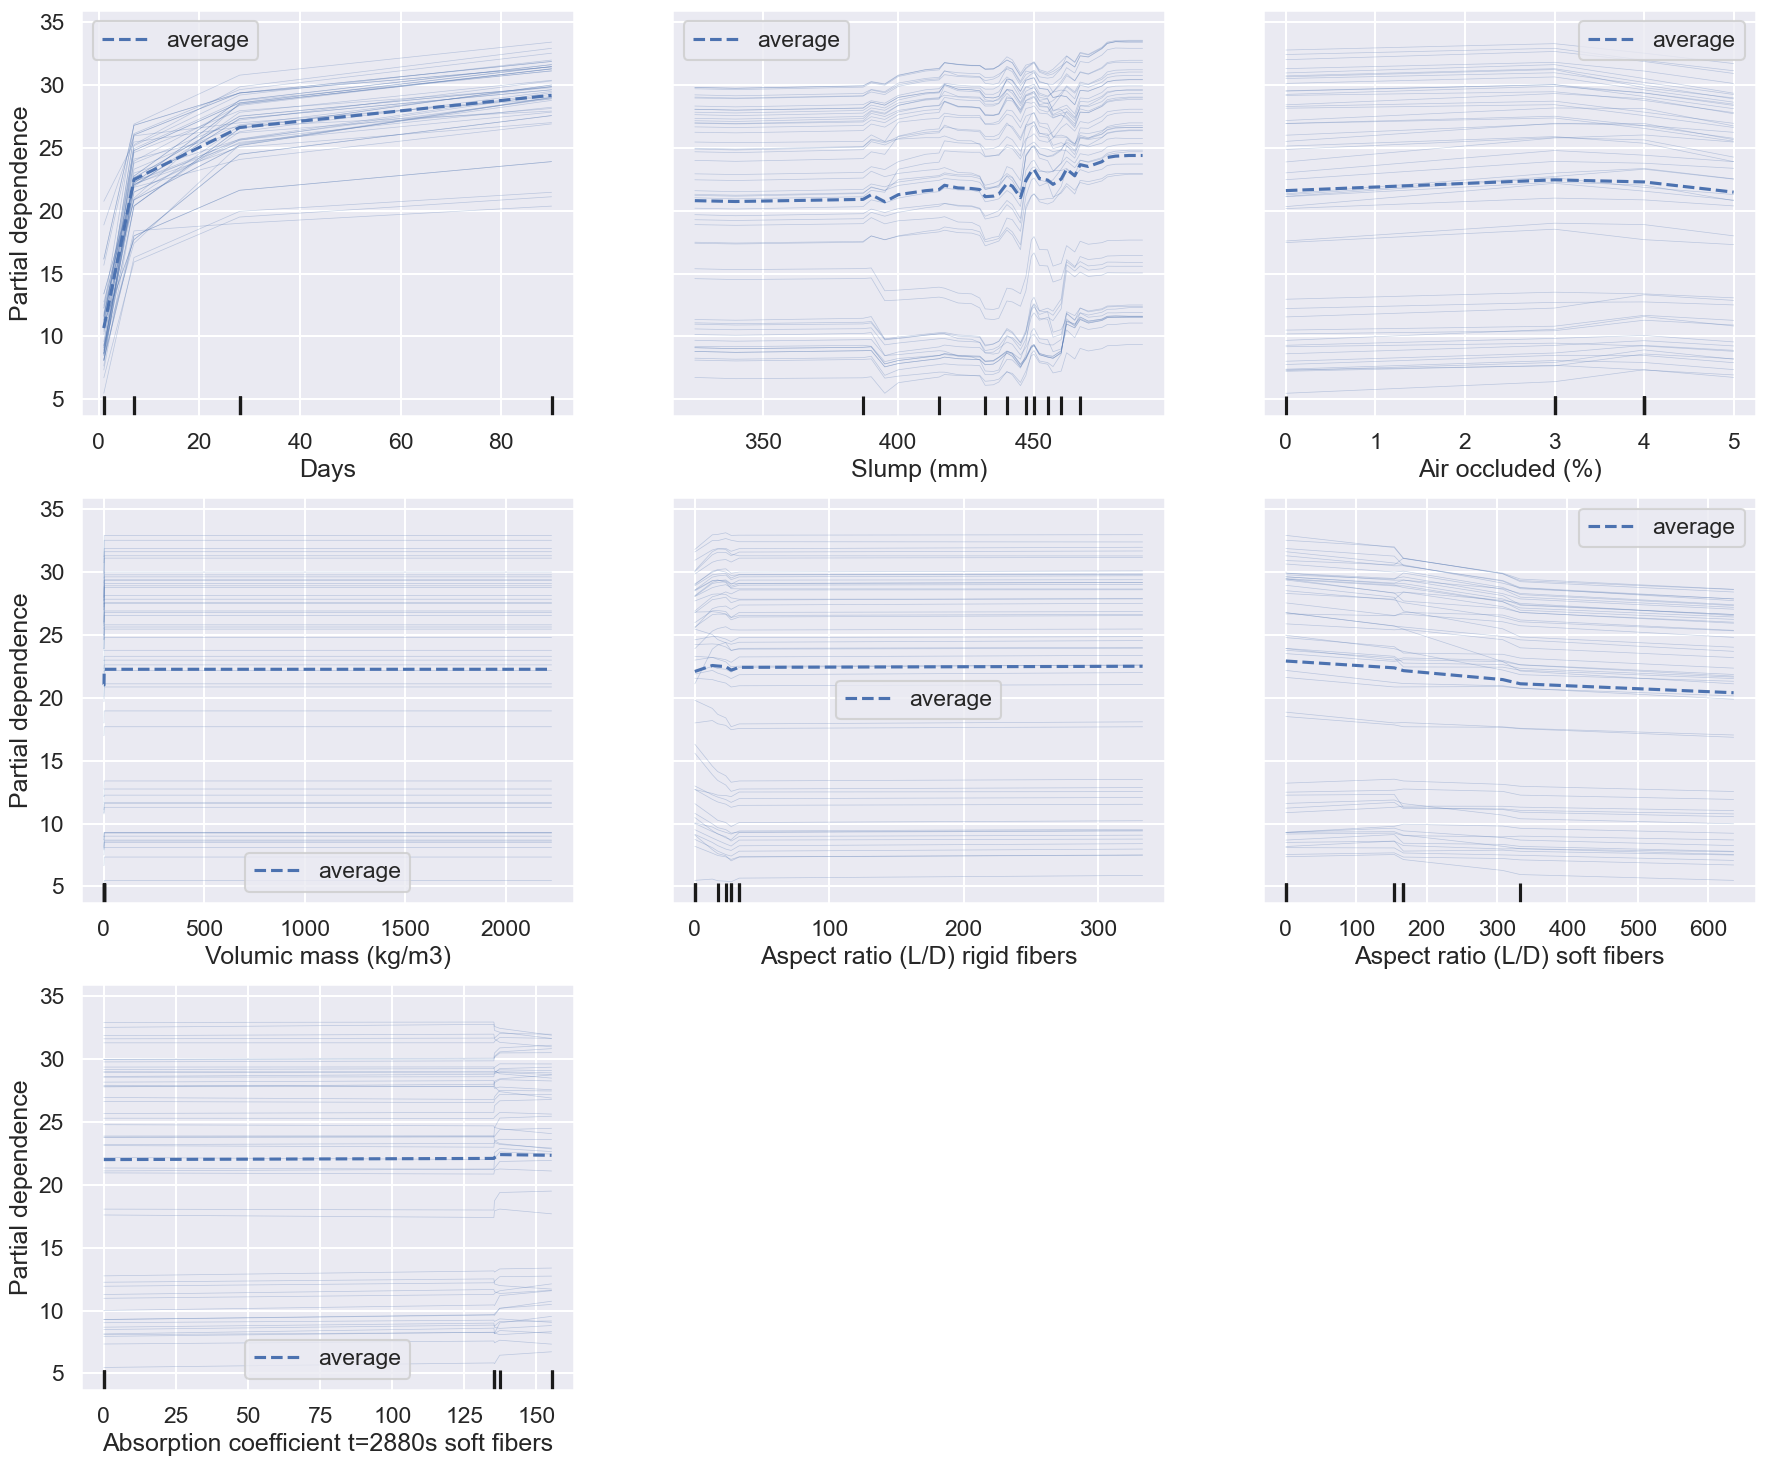

In [ ]:
from sklearn.inspection import PartialDependence       
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import joblib

# Recharge un modèle sauvegardé (ou utilise model_s directement)
seed = 5059
model = joblib.load(f'./saved_models/xgboost_seed_{seed}.pkl')

# Reconstruit le split d'entraînement correspondant à ce seed
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X, y, test_size=0.2, random_state=seed
)

# Les features qui t'intéressent (noms de colonnes si X est un DataFrame)
features = ['Days','Slump (mm)', 'Air occluded (%)', 'Volumic mass (kg/m3)',
             'Aspect ratio (L/D) rigid fibers','Aspect ratio (L/D) soft fibers',
             'Absorption coefficient t=2880s soft fibers', 'chanvre 5', 'chanvre 15', 'bambou 5', 'bambou 15', 'lin 5', 'lin 6', 'lin 15', 'miscanthus 5', 'miscanthus 15', 'ch.antif.', 'ch.strux']  

# Ne pas passer ax : PartialDependenceDisplay crée sa propre grille de subplots
# dimensionnée pour le nombre de features, on redimensionne la figure après coup
display = PartialDependenceDisplay.from_estimator(
    model,
    X_train_s,
    features=features,
    kind='both',
    subsample=50,
    grid_resolution=200,
    random_state=42,
    n_cols=3,
)
display.figure_.set_size_inches(18, 5 * ((len(features) + 2) // 3))
plt.tight_layout()
plt.savefig('pdp_xgboost.png', dpi=500)
plt.show()